In [24]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import warnings
warnings.filterwarnings('ignore', category=UserWarning)

Dataset Shape: (178, 14)

First 3 rows:
    Type  Alcohol  Malic   Ash  Alcalinity  Magnesium  Phenols  Flavanoids  \
0     1    14.23   1.71  2.43        15.6        127     2.80        3.06   
1     1    13.20   1.78  2.14        11.2        100     2.65        2.76   
2     1    13.16   2.36  2.67        18.6        101     2.80        3.24   

   Nonflavanoids  Proanthocyanins  Color   Hue  Dilution  Proline  
0           0.28             2.29   5.64  1.04      3.92     1065  
1           0.26             1.28   4.38  1.05      3.40     1050  
2           0.30             2.81   5.68  1.03      3.17     1185  

Missing Values:
 Type               0
Alcohol            0
Malic              0
Ash                0
Alcalinity         0
Magnesium          0
Phenols            0
Flavanoids         0
Nonflavanoids      0
Proanthocyanins    0
Color              0
Hue                0
Dilution           0
Proline            0
dtype: int64

Summary Statistics:
              Type     Alcohol  

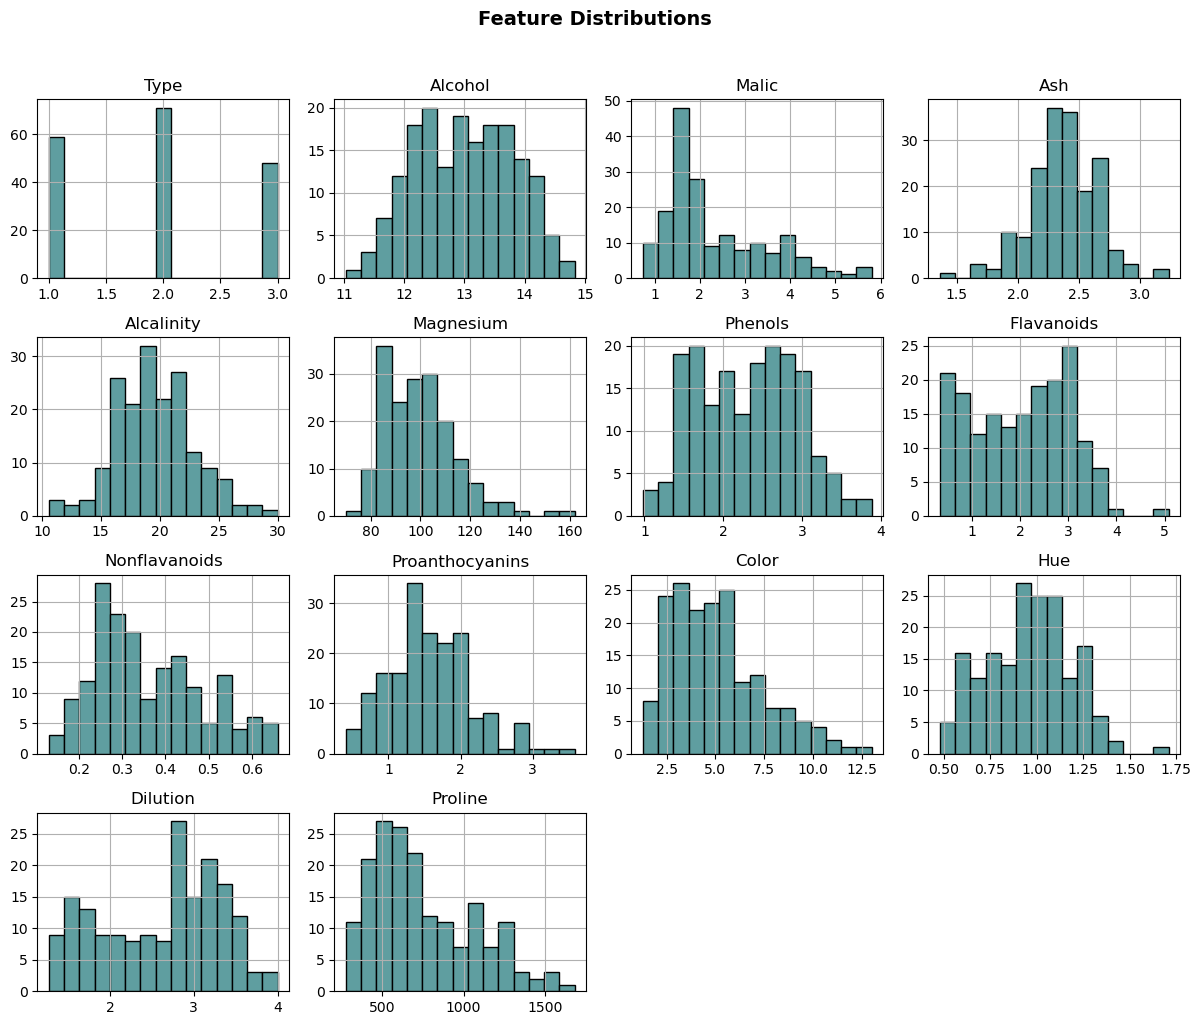

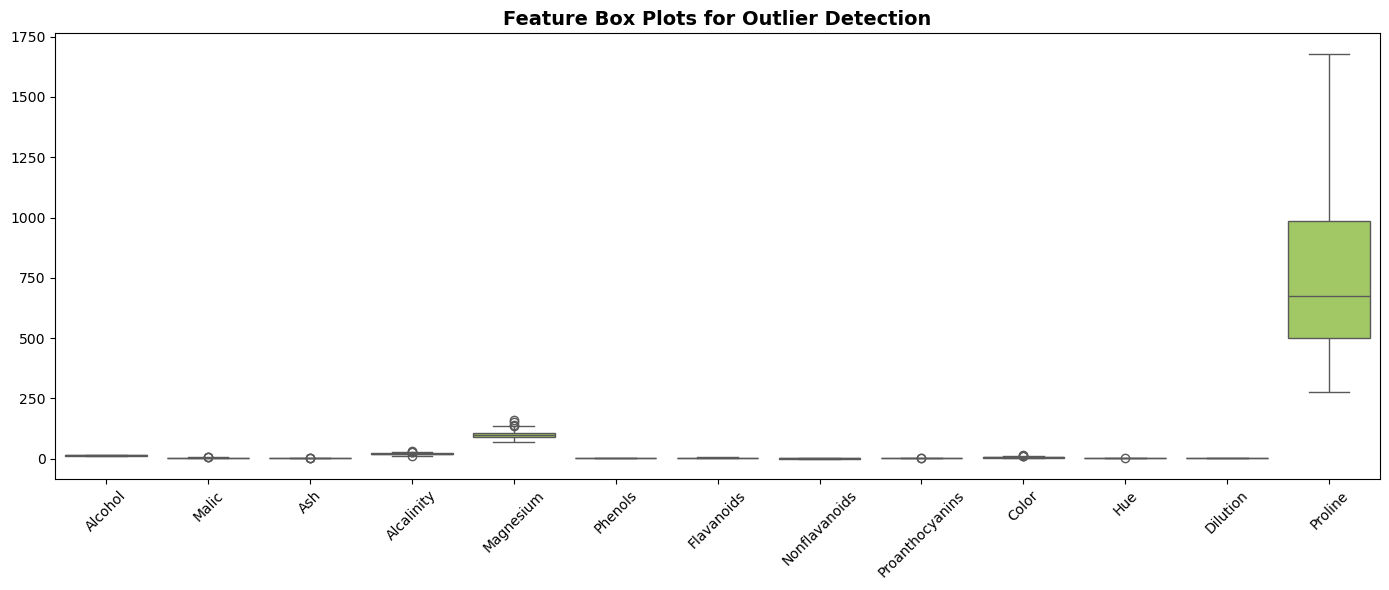

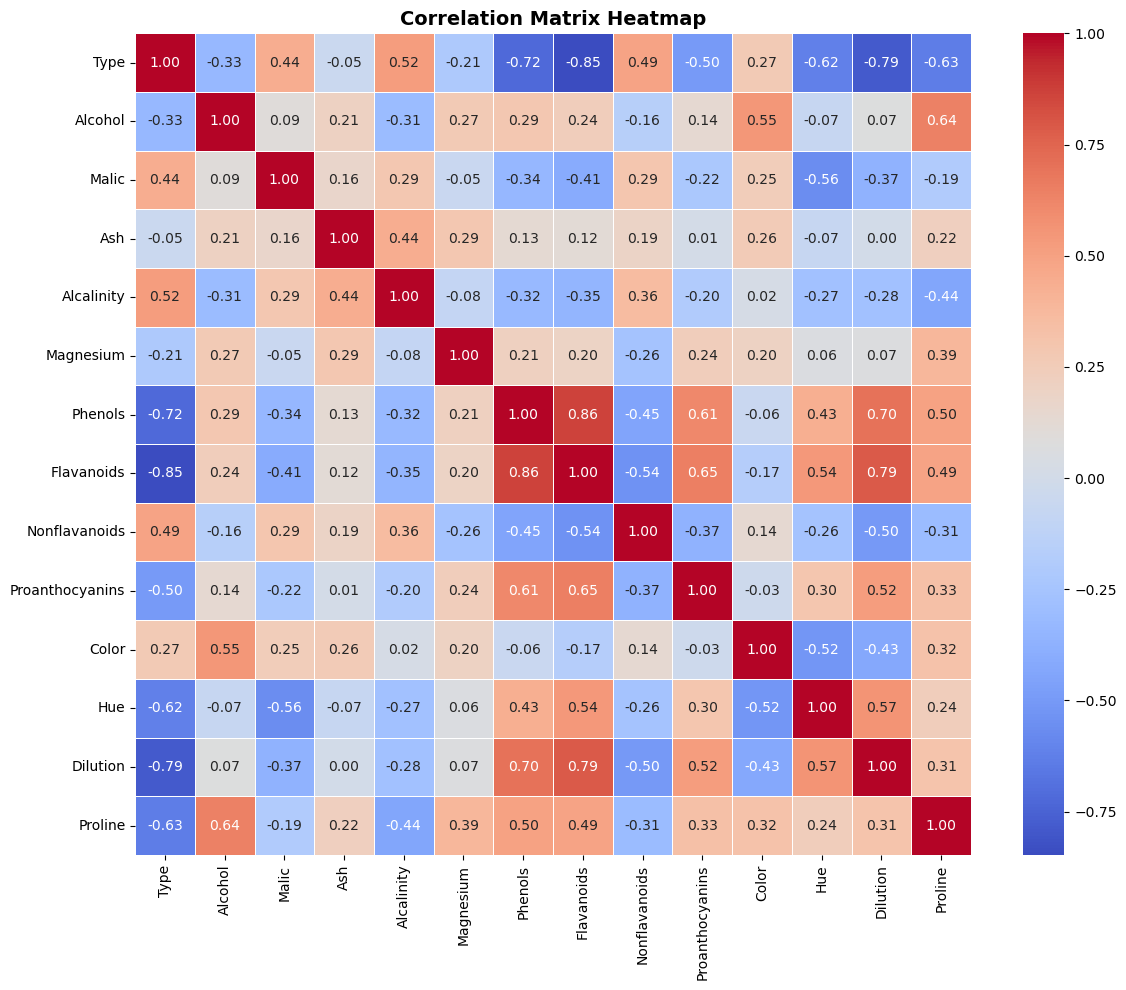

In [25]:
#PCA
# Task 1: Exploratory Data Analysis (EDA)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset and perform basic exploration
df = pd.read_csv('wine.csv')
print("Dataset Shape:", df.shape)
print("\nFirst 3 rows:\n", df.head(3))
print("\nMissing Values:\n", df.isnull().sum())
print("\nSummary Statistics:\n", df.describe())

# 2. Examine feature distributions (Histograms & Box plots)
df.hist(bins=15, figsize=(12, 10), color='cadetblue', edgecolor='black')
plt.suptitle('Feature Distributions', y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))
sns.boxplot(data=df.drop(columns=['Type']), palette='Set2')
plt.title('Feature Box Plots for Outlier Detection', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Investigate correlations between features
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

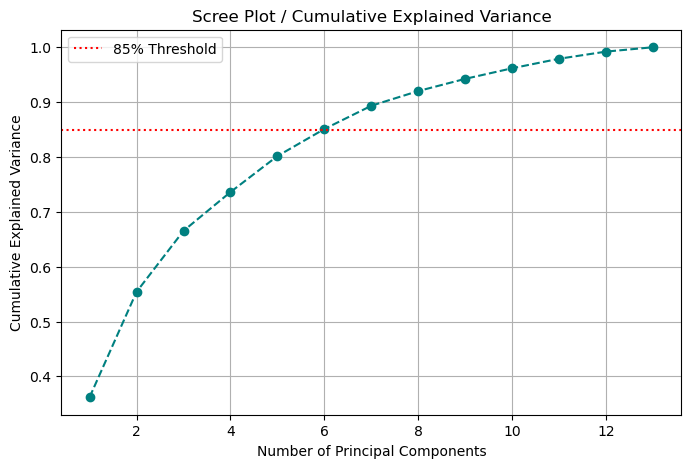

Explained Variance Ratio (2 Components): 55.41%


In [26]:
# Task 2: Dimensionality Reduction with PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Separate features and true labels (for later validation)
X = df.drop(columns=['Type'])
y_true = df['Type']

# 1. Standardize features to mean=0, variance=1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Determine optimal number of components using Cumulative Explained Variance
pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', linestyle='--', color='teal')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Scree Plot / Cumulative Explained Variance')
plt.axhline(y=0.85, color='r', linestyle=':', label='85% Threshold')
plt.grid(True)
plt.legend()
plt.show()

# 3. Transform dataset into principal components (choosing n=2 for 2D visualization)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(f"Explained Variance Ratio (2 Components): {pca.explained_variance_ratio_.sum()*100:.2f}%")

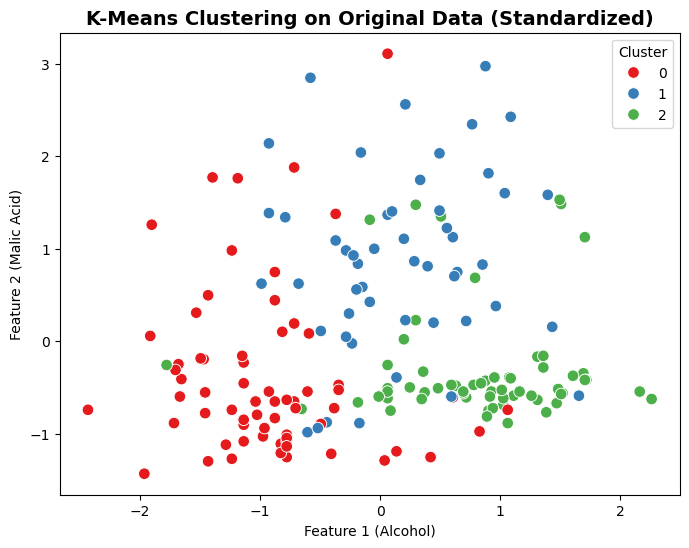

--- Original Data Clustering Performance ---
Silhouette Score: 0.2849
Davies-Bouldin Index: 1.3892


In [27]:
#Task 3: Clustering with Original Data
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Apply K-means clustering on original standardized data (k=3 for 3 wine cultivars)
kmeans_orig = KMeans(n_clusters=3, random_state=42, n_init=10)
orig_clusters = kmeans_orig.fit_predict(X_scaled)

# 2. Visualize clustering results using first two original features
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=orig_clusters, palette='Set1', s=70)
plt.title('K-Means Clustering on Original Data (Standardized)', fontsize=14, fontweight='bold')
plt.xlabel('Feature 1 (Alcohol)')
plt.ylabel('Feature 2 (Malic Acid)')
plt.legend(title='Cluster')
plt.show()

# 3. Evaluate clustering performance
print("--- Original Data Clustering Performance ---")
print(f"Silhouette Score: {silhouette_score(X_scaled, orig_clusters):.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X_scaled, orig_clusters):.4f}")

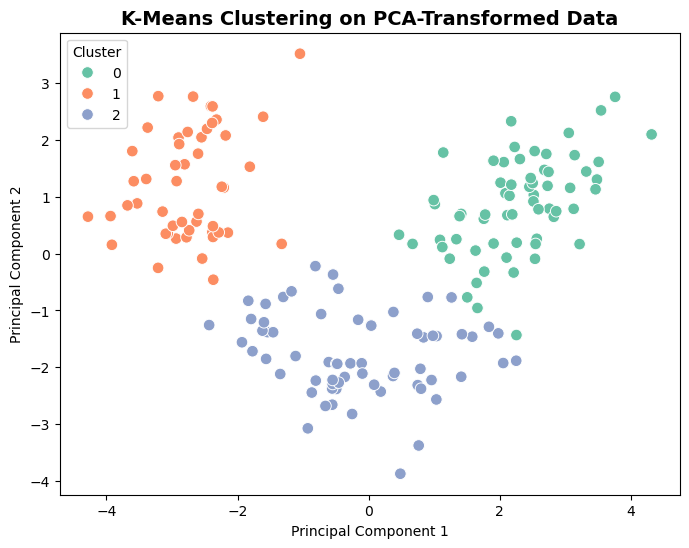

--- PCA-Transformed Clustering Performance ---
Silhouette Score: 0.5611
Davies-Bouldin Index: 0.5973


In [28]:
#Task 4: Clustering with PCA Data
# 1. Apply the same K-means clustering to the PCA-transformed dataset
kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init=10)
pca_clusters = kmeans_pca.fit_predict(X_pca)

# 2. Visualize clustering results obtained from PCA data
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=pca_clusters, palette='Set2', s=70)
plt.title('K-Means Clustering on PCA-Transformed Data', fontsize=14, fontweight='bold')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

# 3. Evaluate and compare performance
print("--- PCA-Transformed Clustering Performance ---")
print(f"Silhouette Score: {silhouette_score(X_pca, pca_clusters):.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X_pca, pca_clusters):.4f}")

In [29]:
#Task 5: Comparison and Analysis
# Create summary comparison table
comparison_df = pd.DataFrame({
    'Metric': ['Silhouette Score (Higher is better)', 'Davies-Bouldin Index (Lower is better)'],
    'Original Data': [
        silhouette_score(X_scaled, orig_clusters),
        davies_bouldin_score(X_scaled, orig_clusters)
    ],
    'PCA-Transformed Data': [
        silhouette_score(X_pca, pca_clusters),
        davies_bouldin_score(X_pca, pca_clusters)
    ]
})

print("\n--- Clustering Performance Comparison ---")
print(comparison_df.to_string(index=False))


--- Clustering Performance Comparison ---
                                Metric  Original Data  PCA-Transformed Data
   Silhouette Score (Higher is better)       0.284859              0.561051
Davies-Bouldin Index (Lower is better)       1.389188              0.597266
